### Agglomerative clustering (Online products)

This is a bit more realistic situation where Agglomerative clustering could be used (too many options)

In this example we aggregate (create summary variables that help clustering) the dataset in order to create a cluster with Agglomerative Clustering, that helps replacing the original Product Category (16 unique options).

In [122]:
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [123]:
# load and test dataset
df = pd.read_csv("../shopping.csv")
df = df.dropna()
df

,Unnamed: 0,CustomerID,Gender,Location,Tenure_Months,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,...,Avg_Price,Delivery_Charges,Coupon_Status,GST,Date,Offline_Spend,Online_Spend,Month,Coupon_Code,Discount_pct
0,0,17850.0,M,Chicago,12.0,16679.0,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,...,153.71,6.5,Used,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0
1,1,17850.0,M,Chicago,12.0,16680.0,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,...,153.71,6.5,Used,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0
2,2,17850.0,M,Chicago,12.0,16696.0,2019-01-01,GGOENEBQ078999,Nest Cam Outdoor Security Camera - USA,Nest-USA,...,122.77,6.5,Not Used,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0
3,3,17850.0,M,Chicago,12.0,16699.0,2019-01-01,GGOENEBQ079099,Nest Protect Smoke + CO White Battery Alarm-USA,Nest-USA,...,81.50,6.5,Clicked,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0
4,4,17850.0,M,Chicago,12.0,16700.0,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,...,153.71,6.5,Clicked,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52919,52919,13155.0,F,California,8.0,22504.0,2019-03-10,GGOEGGCX056399,Gift Card - $250.00,Gift Cards,...,250.00,0.0,Clicked,0.05,3/10/2019,2500.0,1294.22,3,GC30,30.0
52920,52920,18077.0,M,Chicago,34.0,24250.0,2019-03-28,GGOEGGCX056299,Gift Card - $25.00,Gift Cards,...,25.00,0.0,Used,0.05,3/28/2019,2000.0,1066.12,3,GC30,30.0
52921,52921,16085.0,M,California,15.0,39991.0,2019-10-06,GGOEGOCD078399,Google Leather Perforated Journal,Notebooks & Journals,...,10.80,6.0,Clicked,0.05,10/6/2019,3000.0,2230.76,10,NJ10,10.0
52922,52922,16085.0,M,California,15.0,39991.0,2019-10-06,GGOEGOCR078499,Google Spiral Leather Journal,Notebooks & Journals,...,9.60,6.0,Used,0.05,10/6/2019,3000.0,2230.76,10,NJ10,10.0


In [124]:
# how many categories do we have?
print(f"Total categories: {df['Product_Category'].nunique()}")

df['Product_Category'].value_counts()

Total categories: 16


Product_Category
Apparel                 18126
Nest-USA                14013
Office                   6513
Drinkware                3483
Lifestyle                3092
Nest                     2198
Bags                     1882
Headgear                  771
Notebooks & Journals      749
Waze                      554
Nest-Canada               317
Bottles                   268
Accessories               234
Gift Cards                159
Housewares                122
Android                    43
Name: count, dtype: int64

The big idea: generate new aggregate (summarizing) variables, THAT HELP the clustering algorithm to group different product categories together

In [125]:
# you can even add more aggregations:
# Median
# Standard deviation
# Minimum and maximum
# Transaction count
# Possibly selected percentiles

# this is also just one use case of agglomerative clustering
# you can use it also for conventional clustering

# you can also study the hierarchies from a dendrogram
# and cut it into more broad clusters

category_aggregates = df.groupby('Product_Category').agg({
    'Quantity': 'mean',
    'Avg_Price': 'mean',
    'Offline_Spend': 'mean',
    'Online_Spend': 'mean',
    'Discount_pct': 'mean',
    'Month': 'mean',
    'Product_Category': 'count'
}).rename(columns={'Product_Category': 'Transaction_Count'}).reset_index()

category_aggregates

,Product_Category,Quantity,Avg_Price,Offline_Spend,Online_Spend,Discount_pct,Month,Transaction_Count
0,Accessories,4.688034,8.211068,3205.982906,2060.594487,20.726496,10.213675,234
1,Android,1.046512,15.903488,2488.372093,1806.456047,20.465116,5.255814,43
2,Apparel,1.789584,19.788995,2781.733422,1862.619959,20.042480,6.599912,18126
3,Bags,8.115303,29.830797,2761.158342,1833.053289,19.766206,6.235919,1882
4,Bottles,7.798507,3.437201,2727.985075,1835.736940,19.589552,6.123134,268
5,Drinkware,8.757106,10.696893,2800.689061,1882.980342,19.873672,6.157910,3483
6,Gift Cards,1.295597,111.363270,2961.635220,1947.789497,16.226415,7.698113,159
7,Headgear,4.582361,15.879624,2774.059663,1855.049196,19.610895,6.101167,771
8,Housewares,20.360656,2.060574,2586.885246,1836.926148,19.016393,5.540984,122
9,Lifestyle,8.046895,3.860078,2731.338939,1877.553839,19.269082,6.413325,3092


In [126]:
from sklearn.preprocessing import StandardScaler

# select the aggregate features we want to use
# and potentially scale
features = [
    'Quantity',
    'Avg_Price',
    'Offline_Spend',
    'Online_Spend',
    'Discount_pct',
    'Month'
]


# scaling is not strictly required by agglomerative clustering
# but it can be helpful => try with and without scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    category_aggregates[features]
)

# X_scaled = category_aggregates[features]

Let's use agglomerative clustering and combine product categories into clusters (from 16 categories => 8 clusters!)

In [127]:
from sklearn.cluster import AgglomerativeClustering

clusterer = AgglomerativeClustering(
    n_clusters=8,
    linkage='ward'
)

category_aggregates['Cluster'] = clusterer.fit_predict(X_scaled)

Let's study which products were combined into which clusters!

In [ ]:
for cluster in sorted(category_aggregates['Cluster'].unique()):
    categories = category_aggregates.loc[
        category_aggregates['Cluster'] == cluster,
        'Product_Category'
    ].tolist()

    print(f"\nCluster {cluster}:")
    print(categories)

    # notice how clusters 2 and 3 cluster Nest-products next to each other
    # NOTE: similar cluster/categories tend to group together

    # this way the cluster seems like an ordinal category, but technically
    # it's still just a nominal category (you might need OneHotEncoding for the cluster!)


Cluster 0:
['Housewares', 'Notebooks & Journals', 'Office']

Cluster 1:
['Bags', 'Bottles', 'Drinkware', 'Headgear', 'Lifestyle']

Cluster 2:
['Nest']

Cluster 3:
['Nest-Canada', 'Nest-USA']

Cluster 4:
['Accessories']

Cluster 5:
['Gift Cards']

Cluster 6:
['Android']

Cluster 7:
['Apparel', 'Waze']


Let's also create a dendrogram to study the hierarchies!

It's also possible to create "loose clusters" by cutting the dendrogram in higher levels / crossroads!

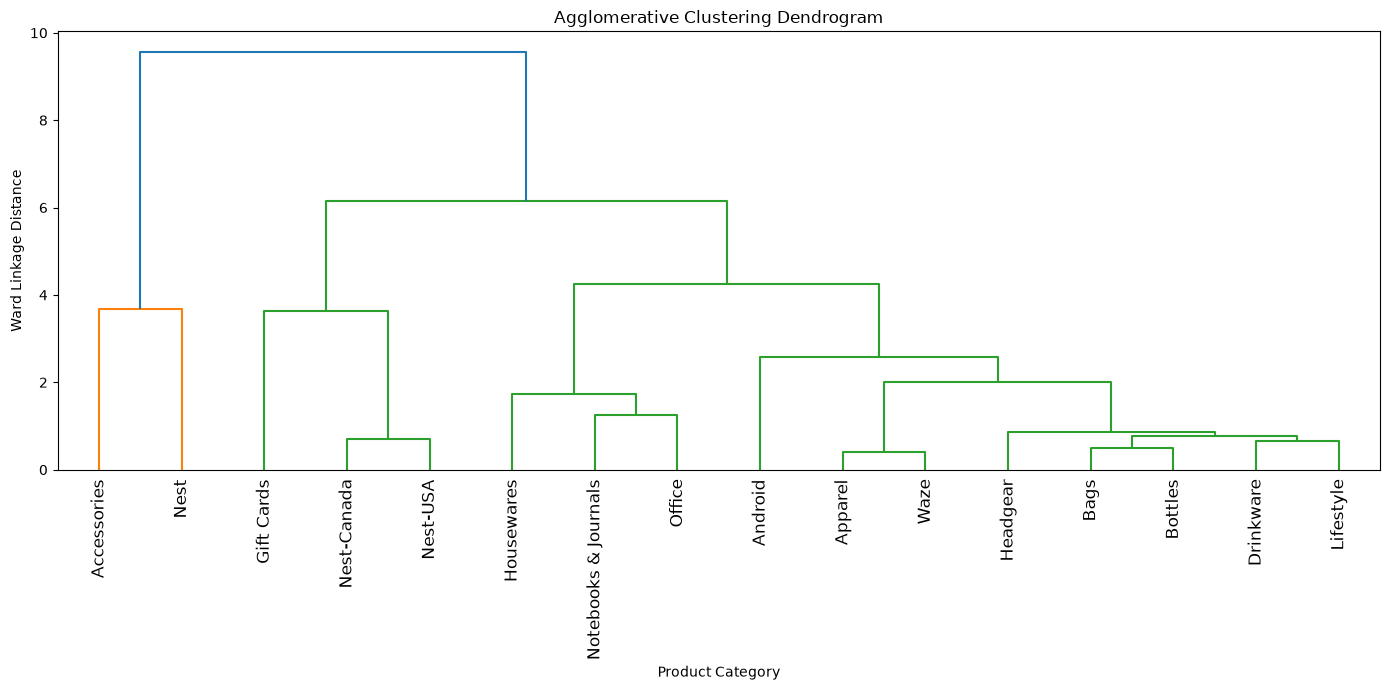

In [129]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 7))

dendrogram(
    Z,
    labels=category_aggregates['Product_Category'].values,
    leaf_rotation=90
)

plt.title('Agglomerative Clustering Dendrogram')
plt.xlabel('Product Category')
plt.ylabel('Ward Linkage Distance')

plt.tight_layout()
plt.show()

Conventional metrics for clustering, silhouette score and ARI.

Silhouette score is more sensible here since it measures how well the cluster describes the original categories. Naturally you wish this to be as close to 1.0 as possible.

ARI is not very useful here, since it literally compares how similar the clustering is to original categories. And since we combined categories into fewer clusters, ARI is going to be usually just 0.0 or close to it.

In [130]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

# if you can get both these metrics either 1 or very close to 1
# is means the clustering describes the original structure extremely well
# and you can replace the original high cardinality column with the cluster values instead

# Silhouette Score
sil_score = silhouette_score(
    X_scaled,
    category_aggregates['Cluster']
)

# ARI
ari_score = adjusted_rand_score(
    category_aggregates['Product_Category'],
    category_aggregates['Cluster']
)

print(f"Silhouette Score: {sil_score:.4f}")

# ARI doesn't help here since we are trying to measure a different thing here
# replacement for the original category
print(f"Adjusted Rand Index: {ari_score:.4f}")

Silhouette Score: 0.3194
Adjusted Rand Index: 0.0000


Finally, map the cluster value back to original DataFrame!

In [131]:
category_mapping = category_aggregates[
    ['Product_Category', 'Cluster']
].copy()

In [132]:
df = df.merge(
    category_mapping,
    on='Product_Category',
    how='left'
)

After this, you can technically remove the original product category, if you're happy with the clustering result!

In [133]:
# note => the new cluster is a nominal category!
df

,Unnamed: 0,CustomerID,Gender,Location,Tenure_Months,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,...,Delivery_Charges,Coupon_Status,GST,Date,Offline_Spend,Online_Spend,Month,Coupon_Code,Discount_pct,Cluster
0,0,17850.0,M,Chicago,12.0,16679.0,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,...,6.5,Used,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0,3
1,1,17850.0,M,Chicago,12.0,16680.0,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,...,6.5,Used,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0,3
2,2,17850.0,M,Chicago,12.0,16696.0,2019-01-01,GGOENEBQ078999,Nest Cam Outdoor Security Camera - USA,Nest-USA,...,6.5,Not Used,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0,3
3,3,17850.0,M,Chicago,12.0,16699.0,2019-01-01,GGOENEBQ079099,Nest Protect Smoke + CO White Battery Alarm-USA,Nest-USA,...,6.5,Clicked,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0,3
4,4,17850.0,M,Chicago,12.0,16700.0,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,...,6.5,Clicked,0.10,1/1/2019,4500.0,2424.50,1,ELEC10,10.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52519,52919,13155.0,F,California,8.0,22504.0,2019-03-10,GGOEGGCX056399,Gift Card - $250.00,Gift Cards,...,0.0,Clicked,0.05,3/10/2019,2500.0,1294.22,3,GC30,30.0,5
52520,52920,18077.0,M,Chicago,34.0,24250.0,2019-03-28,GGOEGGCX056299,Gift Card - $25.00,Gift Cards,...,0.0,Used,0.05,3/28/2019,2000.0,1066.12,3,GC30,30.0,5
52521,52921,16085.0,M,California,15.0,39991.0,2019-10-06,GGOEGOCD078399,Google Leather Perforated Journal,Notebooks & Journals,...,6.0,Clicked,0.05,10/6/2019,3000.0,2230.76,10,NJ10,10.0,0
52522,52922,16085.0,M,California,15.0,39991.0,2019-10-06,GGOEGOCR078499,Google Spiral Leather Journal,Notebooks & Journals,...,6.0,Used,0.05,10/6/2019,3000.0,2230.76,10,NJ10,10.0,0


In [134]:
# it's all about a compromise => average clustering result vs too many one hot encoded variables
# too many one hot encoded variables bring usually noise to the dataset

# this is one of the big dilemmas in ML engineering => how to handle categoricals
# should everything be a separate variable? (huge amounts of potential noise)
# technically the noise here is a form of variance and sparsity of values

# or should we use agglomerative clustering (one variable, but lost 
# accuracy regarding category relationships)

# NOTE: some tree-based models like Random Forest or XGBoost can handle
# nominal categories even if they are converted with a LabelEncoder (just
# random integer for each categories), since they still treat them as separate
# categories

# however, when having too many values, the tree based models can struggle
# with many options, since they have to make more and more splits between
# categories while creating the decision trees

https://www.datanovia.com/en/wp-content/uploads/dn-tutorials/003-hierarchical-clustering-in-r/figures/002-agglomerative-clustering-cutree-cut-dendrogram-1.png

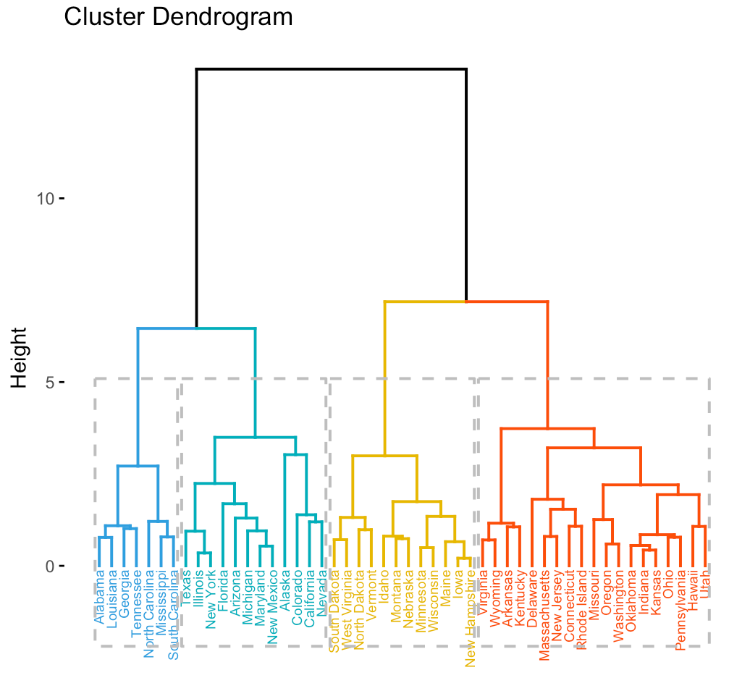